# PEPSI: a night of the K dwarf TOI-2076

This notebook shows how gtellcorr corrects a time series of spectra. We use one night of
PEPSI observations of TOI-2076 (LBT, 2025 June 19): 60 exposures taken with the red arm
and cross-disperser 5, which cover 623-742 nm at a resolving power of about 130 000.
Every exposure is fitted on its own, with the atmospheric profile of its own epoch. The
star is described by a synthetic template, and the wavelength solution of each exposure
is corrected on the telluric lines.

We proceed in four steps:

1. **The observations.** We read the night and see how the telluric lines change with
   airmass.
2. **The atmospheric profiles.** gtellcorr builds one profile per exposure from ERA5.
3. **The fit.** We write down the model, go through every parameter of the fit and fit
   the 60 exposures.
4. **Through the night.** We compare the fitted water vapour with the humidity measured
   at the telescope, look at the fit of one exposure and at the corrected H-alpha
   region, and use the fitted wavelength correction on the stellar radial velocities.

**What you need.** gtellcorr with its LBLRTM bundle and reference files, pySME and a
VALD line list for the template (the `stellar_linelist` setting), and the 60 spectra
`pepsir.20250619.*.dxt.nor` in `$GTELLCORR_PAPER_DATA/pepsi_toi2076/`. Apart from
`pepsir.20250619.118`, which comes with the gtellcorr example data, these spectra are
not public yet. The notebook is published with its results, so the steps can be
followed without them.

The atmospheric profiles come from ERA5, which needs a Copernicus account
(`WEATHER_KEYS`). The first run takes a while: it synthesises the template and computes
the optical depths of every exposure with LBLRTM. Later runs reuse both, and reuse the
fit of every exposure whose result is already in the output directory.

In [1]:
import json
import os
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import EarthLocation, SkyCoord
from astropy.io import fits
from astropy.time import Time
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import gtellcorr as gtc
from gtellcorr.constants import C_KMS
from gtellcorr.data.atmosphere import full_profile_for_exposure
from gtellcorr.data.atmosphere.profile import rh_to_vmr_ppmv
from gtellcorr.data.products import load_exposure_order
from gtellcorr.fitting import build_fit_spec
from gtellcorr.plotting import plot_order_fit, plot_profiles

data = Path(os.environ.get("GTELLCORR_PAPER_DATA", "paper_data"))
output = Path(os.environ.get("GTELLCORR_PAPER_OUT", "paper_runs")) / "pepsi_toi2076_night"
settings = gtc.Settings.load()
plt.rcParams["figure.dpi"] = 72  # keeps the figures in the notebook small
print("gtellcorr", gtc.__version__)

gtellcorr 0.10.0


## 1. The observations

We first describe the target: `gtc.Star` holds the stellar parameters from which the
template is synthesised.

`gtc.Observation.from_directory` then reads every spectrum in the directory with the
PEPSI instrument description. From each header it takes the epoch, the site, the
airmass, the resolving power (from the fibre) and the weather measured at the
telescope; each exposure is an `Exposure` object.

60 exposures, 03:22-09:01 UTC, airmass 1.01-1.99, R = 130000


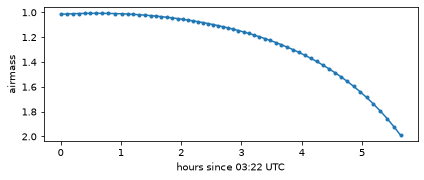

In [2]:
star = gtc.Star(name="TOI-2076", teff=5180.0, logg=4.608, feh=0.0, vsini_kms=5.0, vsys_kms=-12.5)
obs = gtc.Observation.from_directory(data / "pepsi_toi2076", instrument="LBT/PEPSI", target=star)
exposures = obs.exposures
t0 = exposures[0].time_utc
hours = np.array([(e.time_utc - t0).total_seconds() / 3600 for e in exposures])
airmass = np.array([e.airmass for e in exposures])
assert np.all(np.diff(hours) > 0)  # the exposures are in time order
print(
    f"{len(obs)} exposures, {t0:%H:%M}-{exposures[-1].time_utc:%H:%M} UTC, airmass "
    f"{airmass.min():.2f}-{airmass.max():.2f}, R = {exposures[0].resolution:.0f}"
)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(hours, airmass, ".-")
ax.invert_yaxis()
ax.set_xlabel(f"hours since {t0:%H:%M} UTC")
ax.set_ylabel("airmass")
fig.tight_layout()

The target is close to the zenith at the start of the night and sets towards its
end. To see what has to be corrected, let's compare the exposures at the lowest and the
highest airmass in two regions: the O{sub}`2` γ band near 628 nm and a group of water
lines near 718 nm.

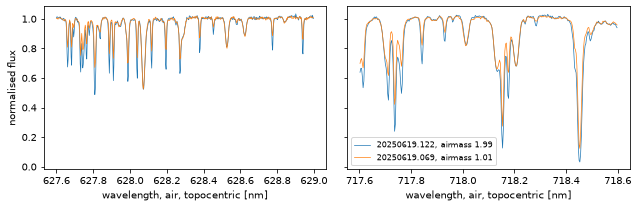

In [3]:
low, high = int(np.argmin(airmass)), int(np.argmax(airmass))
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for index in (high, low):
    order = obs.read_order(exposures[index], 0)
    label = f"{exposures[index].name[7:19]}, airmass {airmass[index]:.2f}"
    for ax, (lo, hi) in zip(axes, ((627.6, 629.0), (717.6, 718.6)), strict=True):
        sel = (order.wave_fit > lo) & (order.wave_fit < hi)
        ax.plot(order.wave_fit[sel], order.flux[sel], lw=0.7, label=label)
axes[0].set_ylabel("normalised flux")
axes[1].legend(fontsize=8, loc="lower left")
for ax in axes:
    ax.set_xlabel("wavelength, air, topocentric [nm]")
fig.tight_layout()

The lines of both molecules are deeper at high airmass, where the light crosses more
air. The O{sub}`2` lines follow the airmass alone, because O{sub}`2` is well mixed; the
water lines also follow the amount of water above the telescope, which changes during
the night. The fit therefore has to find the water column of every exposure.

## 2. The atmospheric profiles

The telluric transmission is computed with LBLRTM from a profile of the atmosphere
above the telescope: pressure, temperature and the abundances of the molecules, from
the ground to 120 km. gtellcorr builds one profile per exposure:

- the lower atmosphere comes from the ERA5 reanalysis (`atmosphere.lower_backend =
  "era5_cdsapi"`), at the grid point nearest to LBT and at the hour nearest to the
  middle of the exposure (ERA5 is hourly);
- the upper atmosphere comes from the NRLMSIS-00 model (`atmosphere.upper_source =
  "msis00"`); the two are joined over a blend zone 6 km wide.

`full_profile_for_exposure` returns the profile of one exposure; the fit calls it for
every exposure, and the profiles are cached on disk. Let's plot the profiles of the
first, middle and last exposures:

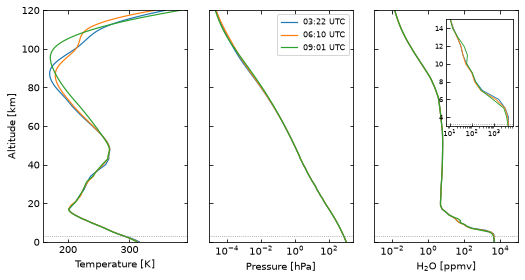

In [4]:
picks = (0, len(obs) // 2, len(obs) - 1)
profiles = {}
for index in picks:
    e = exposures[index]
    profiles[f"{e.time_utc:%H:%M} UTC"] = full_profile_for_exposure(
        e, obs.instrument, settings=settings
    )
fig, axes = plot_profiles(
    profiles, site_alt_km=exposures[0].site.alt_m / 1000, inset_z_km=(3.0, 15.0)
)

The fit does not change the shape of these profiles; it scales the column of each
fitted molecule, as described next. In Section 4 we compare the scaled water with the
water measured at the telescope.

## 3. The fit

### The model

gtellcorr fits every order of every exposure with the model

$$F(\lambda) = C(\lambda)\, M(\lambda)\, \left[K_R \ast T\right](\lambda),$$

where:

- $T$ is the telluric transmission, $T = \exp\left[-\sum_m s_m \tau_m - \tau_{\rm
  fixed}\right]$. Here $\tau_m$ is the optical depth of the fitted molecule $m$,
  computed once with LBLRTM from the exposure's profile, and $s_m$ is its **relative
  column**: the column in the spectrum as a multiple of the column in the profile.
  $\tau_{\rm fixed}$ holds the molecules that are not fitted and the continuum
  absorption (water and O{sub}`2` continua, Rayleigh scattering), both at their
  profile values.
- $K_R$ is the line-spread function, a Gaussian of resolving power $R$. It acts on the
  transmission only; the template is already at the resolution of the spectrograph.
- $M$ is the stellar spectrum. Here it is a template synthesised with pySME and placed
  at the radial velocity of the star in the exposure, measured beforehand by
  cross-correlation.
- $C$ is the continuum, a polynomial in wavelength. It is not a free parameter of the
  non-linear fit: at every step of the fit it is solved by linear least squares, with
  outliers clipped.

A wavelength correction can be added to the model: a velocity $v$ by which the
telluric model is shifted before it is compared with the data. Since the telluric lines
are at rest in the observatory frame, $v$ measures the error of the wavelength solution
of the exposure.

### The settings

The fit is set by a `gtc.FitConfig`. Only two settings differ from the defaults here:

- `stellar = "template"`: the star is modelled with a synthetic template ($M$ above).
  The default, `"mask"`, masks the stellar lines instead;
- `wavelength.fit = true`: the wavelength correction $v$ is fitted, one constant
  velocity per order (`wavelength.order = 0`). The PEPSI spectrum is a single merged
  order, so this is one velocity per exposure.

`build_fit_spec` turns the configuration into the fit of one order: the free
parameters with their start values and bounds, and everything that is held fixed.
Let's print it for the first exposure:

In [5]:
config = gtc.FitConfig.from_dict({"stellar": "template", "wavelength": {"fit": True}})

order = obs.read_order(exposures[0], 0)
lo_nm, hi_nm = float(order.wave_fit.min()), float(order.wave_fit.max())
spec = build_fit_spec(
    (lo_nm, hi_nm),
    config=config,
    instrument=obs.instrument,
    order=0,
    resolution=exposures[0].resolution,
)

print(f"Order 0: {lo_nm:.2f}-{hi_nm:.2f} nm (air, topocentric), {order.wave_fit.size} pixels\n")
print("Free parameters                start        bounds")
for m in spec.molecules:
    lo, hi = spec.relcol_bounds[m]
    print(f"  relative column s_{m.upper():<11}{spec.relcol_init[m]:>8.2f}        {lo:g} to {hi:g}")
lo, hi = spec.resolution_bounds
print(
    f"  resolving power R ({spec.lsf_kind})  {spec.resolution_init:>8.0f}"
    f"        {lo:.0f} to {hi:.0f}"
)
lo, hi = spec.wave_shift_bounds
print(f"  wavelength correction v [km/s]{0.0:>6.2f}        {lo:g} to {hi:g}")

lo, hi = spec.continuum_sigma_clip
print("\nSolved linearly at every step")
print(f"  continuum C: polynomial of degree {spec.continuum_order}, pixels below -{lo:g} or above")
print(f"  +{hi:g} sigma clipped ({spec.continuum_niter} iteration); the stored continuum is")
print(f"  refitted after the fit with {spec.continuum_output_niter} clipping iterations")

sm, masks = config.stellar_model, config.masks
activity = [w for w in masks.activity_windows_nm if w[1] > lo_nm and w[0] < hi_nm]
print("\nHeld fixed")
print(
    f"  stellar template M: {sm.backend} ({sm.pysme.atmosphere} atmospheres, "
    f"{sm.pysme.abundances} abundances),"
)
print(f"    placed at the cross-correlation RV; template velocity fitted: {spec.fit_stellar_shift}")
print(
    f"  optical depths: LBLRTM, continua {config.telluric.continuum_mode!r}, computed "
    f"{config.telluric.wave_margin_nm:g} nm beyond the order"
)
print("\nLeft out of the fit (still corrected)")
print(f"  cores of strong telluric lines, T < {masks.strong_telluric.threshold:g}")
print(f"  stellar activity lines: {', '.join(f'{a:g}-{b:g} nm' for a, b in activity)}")

Order 0: 623.29-741.80 nm (air, topocentric), 45183 pixels

Free parameters                start        bounds
  relative column s_H2O            1.00        0.01 to 100
  relative column s_O2             1.00        0.5 to 1.5
  resolving power R (gauss)    130000        119600 to 140400
  wavelength correction v [km/s]  0.00        -1 to 1

Solved linearly at every step
  continuum C: polynomial of degree 5, pixels below -2 or above
  +3 sigma clipped (1 iteration); the stored continuum is
  refitted after the fit with 5 clipping iterations

Held fixed
  stellar template M: pysme (marcs2012 atmospheres, grevesse2007 abundances),
    placed at the cross-correlation RV; template velocity fitted: False
  optical depths: LBLRTM, continua 'full', computed 20 nm beyond the order

Left out of the fit (still corrected)
  cores of strong telluric lines, T < 0.05
  stellar activity lines: 654.8-657.8 nm


Four parameters are fitted: the relative columns of H{sub}`2`O and O{sub}`2`, the
resolving power and the wavelength correction. The bounds of the columns are wide for
water, whose amount varies a lot, and narrow for O{sub}`2`, which should be close to the
profile. $R$ starts at the value of the 200 µm fibre and may move by 8 % either way.
Two kinds of pixels do not enter the fit: the cores of the strong telluric lines, where
the transmission is below 5 % and the data carry little information, and the
H-alpha line (654.8-657.8 nm), whose activity-driven changes the template cannot follow.
Both are still corrected with the fitted transmission. `gtellcorr.config.dumps_config(config)`
prints the complete configuration, defaults included, as TOML.

Let's fit the night. `gtc.run` synthesises the template, measures the stellar RV of
every exposure against it, fits every exposure and writes the results to `output`:

In [6]:
result = gtc.run(obs, config, output_dir=output, settings=settings, plot=False)
summary = result.summary.set_index("exposure")
relcol = summary["relcol"].map(json.loads)
h2o = np.array([relcol[e.name]["h2o"] for e in exposures])
o2 = np.array([relcol[e.name]["o2"] for e in exposures])
converged = summary["converged"].astype(str).str.lower().eq("true")
print(f"{len(summary)} exposures fitted, {int(converged.sum())} converged")
print(f"relative column H2O: median {np.median(h2o):.3f}, range {h2o.min():.3f}-{h2o.max():.3f}")
print(f"relative column O2:  median {np.median(o2):.4f}, range {o2.min():.4f}-{o2.max():.4f}")

60 exposures fitted, 60 converged
relative column H2O: median 0.947, range 0.863-0.990
relative column O2:  median 1.0221, range 0.9998-1.0331


## 4. Through the night

With the 60 fits done, we look at the night as a whole: the fitted water against an
independent measurement, the fit of one exposure, the corrected spectra around H-alpha,
and the radial velocities of the star.

### 4.1 Water vapour

The relative column $s_{\rm H_2O}$ scales the whole ERA5 water profile of an exposure.
To check that it is physically meaningful, we turn it into a volume mixing ratio (VMR)
at the telescope, $s_{\rm H_2O}$ times the VMR of the profile at the altitude of LBT,
and compare it with the VMR derived from the relative humidity, temperature and pressure
measured by the LBT weather station. PEPSI writes these into every header (`LBTH`,
`LBTT`, `LBTP`), and gtellcorr reads them into `Exposure.weather`.

spectroscopic / site-derived VMR: median 1.034, range 0.921-1.134


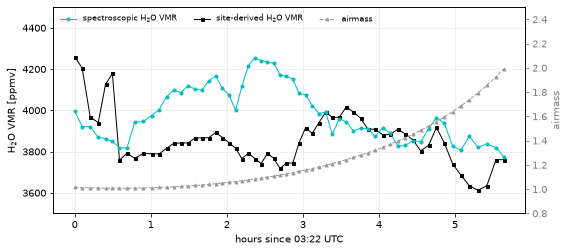

In [7]:
vmr_fit, vmr_site = [], []
for e, s in zip(exposures, h2o, strict=True):
    profile = full_profile_for_exposure(e, obs.instrument, settings=settings)
    vmr_profile = np.interp(e.site.alt_m / 1000, profile["z_km"], profile["H2O_ppmv"])
    vmr_fit.append(s * vmr_profile)
    w = e.weather
    vmr_site.append(float(rh_to_vmr_ppmv(w.RH_pct, w.T_K, w.P_hpa)))
vmr_fit, vmr_site = np.array(vmr_fit), np.array(vmr_site)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax_am = ax.twinx()
ax_am.plot(hours, airmass, color="0.6", ls="--", marker="^", ms=3, lw=1, label="airmass")
ax_am.set_ylabel("airmass", color="0.5")
ax_am.tick_params(axis="y", colors="0.5")
ax_am.set_ylim(0.8, 2.5)
ax.plot(
    hours,
    vmr_fit,
    "o-",
    color="c",
    ms=3,
    lw=1,
    label="spectroscopic H$_2$O VMR",
    zorder=5,
)
ax.plot(
    hours,
    vmr_site,
    "s-",
    color="k",
    ms=3,
    lw=1,
    label="site-derived H$_2$O VMR",
    zorder=4,
)
ax.set_xlabel(f"hours since {t0:%H:%M} UTC")
ax.set_ylabel("H$_2$O VMR [ppmv]")
ax.set_ylim(3500, 4500)
ax.grid(alpha=0.25)
handles = ax.get_legend_handles_labels()[0] + ax_am.get_legend_handles_labels()[0]
ax.legend(handles=handles, loc="upper left", ncol=3, frameon=False, fontsize=8)
fig.tight_layout()

ratio = vmr_fit / vmr_site
print(
    f"spectroscopic / site-derived VMR: median {np.median(ratio):.3f}, "
    f"range {ratio.min():.3f}-{ratio.max():.3f}"
)

The two estimates agree in their overall scale: the spectroscopic VMR is on median
3 % above the site-derived one. They do not follow each other exposure by exposure (the
ratio ranges from 0.92 to 1.13), and this is expected. The spectrum measures the water
integrated along the line of sight, and $s_{\rm H_2O}$ scales the vertical profile as a
whole, whereas the weather station measures the air at the telescope only. A different
vertical distribution of the water, changes along the line of sight and the
uncertainties of both the profile and the station separate the two. Their agreement in
scale shows that the fitted relative columns describe the real atmosphere rather than
acting as free scaling factors.

### 4.2 The fit of one exposure

Next we look at a single fit, `pepsir.20250619.118`, the exposure that comes with the
gtellcorr example data. `plot_order_fit` draws two panels. The upper one shows the
observed spectrum with the fitted continuum $C$, the stellar model $C M$ and the
telluric model $C T$; grey bands mark the pixels left out of the fit. The lower one
shows the corrected spectrum, $F / (C T)$, with its 1σ uncertainty.

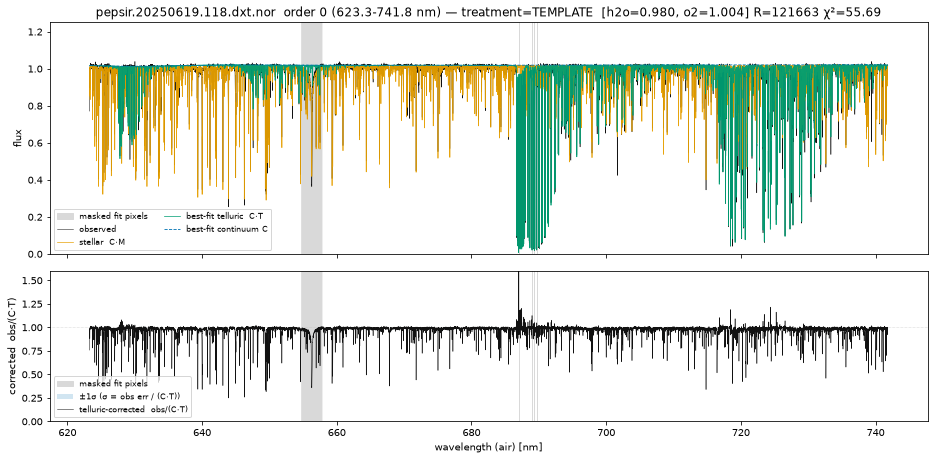

In [8]:
(path,) = result.data_dir.glob("pepsir.20250619.118*_corrected_all_orders.fits")
fig, axes = plot_order_fit(str(path), order=0, out=False)

The telluric model reproduces the O{sub}`2` γ (627-630 nm) and B (687-695 nm) bands and
the water lines across the order, the strongest of them beyond 715 nm. Where only
telluric lines were, the corrected spectrum is flat at 1, and the stellar lines are left
as they are. The largest residuals are at the head of the B band near 687 nm, where the
lines are saturated: their cores are left out of the fit, and the uncertainty of the
corrected flux grows as $1/T$ there.

### 4.3 H-alpha through the night

H-alpha is a common tracer of stellar activity, and around it the spectrum is crossed by
water lines. We take every sixth exposure, ten in all, and plot them before and after
the correction in the rest frame of the star. Each spectrum is moved to that frame with
the RV measured for its exposure, which `gtc.run` writes to the RV table
`Radial_Velocities/data/*_rv.csv`. The telluric model of the first exposure is drawn
above the spectra, shifted up by 0.2.

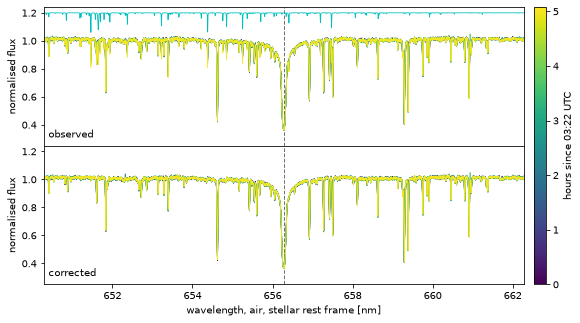

In [9]:
(rv_table,) = (result.root / "Radial_Velocities" / "data").glob("*_rv.csv")
rv = pd.read_csv(rv_table).set_index("file")
halpha_nm, half_width_nm = 656.2808, 6.0

picks = list(range(0, len(exposures), 6))[:10]
norm = Normalize(hours[picks[0]], hours[picks[-1]])
fig = plt.figure(figsize=(9, 5))
grid = fig.add_gridspec(2, 2, width_ratios=(1, 0.025), hspace=0, wspace=0.04)
axes = [fig.add_subplot(grid[0, 0])]
axes.append(fig.add_subplot(grid[1, 0], sharex=axes[0], sharey=axes[0]))
for i in picks:
    e = exposures[i]
    (path,) = result.data_dir.glob(f"{e.path.stem}_*corrected_all_orders.fits")
    r = load_exposure_order(path, order=0)
    wave = r["wave_fit"] / (1 + rv.loc[e.name, "rv_kms"] / C_KMS)  # stellar rest frame
    sel = np.abs(wave - halpha_nm) < half_width_nm
    color = plt.cm.viridis(norm(hours[i]))
    axes[0].plot(wave[sel], r["flux_obs"][sel], color=color, lw=0.8, alpha=0.9)
    axes[1].plot(wave[sel], r["flux_corrected"][sel], color=color, lw=0.8, alpha=0.9)
    if i == picks[0]:
        axes[0].plot(wave[sel], r["tell_model"][sel] + 0.2, color="c", lw=0.8)
for ax, title in zip(axes, ("observed", "corrected"), strict=True):
    ax.axvline(halpha_nm, color="0.45", ls="--", lw=1, zorder=0)
    ax.set_ylabel("normalised flux")
    ax.text(0.01, 0.06, title, transform=ax.transAxes)
axes[0].set_ylim(0.25, 1.24)
axes[0].set_xlim(halpha_nm - half_width_nm, halpha_nm + half_width_nm)
axes[0].tick_params(labelbottom=False)
axes[1].set_xlabel("wavelength, air, stellar rest frame [nm]")
colorbar = fig.colorbar(
    ScalarMappable(norm, "viridis"),
    cax=fig.add_subplot(grid[:, 1]),
    label=f"hours since {t0:%H:%M} UTC",
)

Before the correction, narrow water lines run across the whole region, including the
wings of H-alpha. After it they are removed in every exposure, and no systematic
residuals are left over the 5.6 hours. The H-alpha line itself was left out of the fit
(Section 3), but it is corrected with the transmission fitted on the rest of the
order.

### 4.4 Radial velocities and the wavelength solution

Before the telluric fit, `gtc.run` measures the RV of the star in every exposure by
cross-correlating each order with the template, with the telluric lines masked. The
RV table holds, for each exposure, the weighted mean of the per-order RVs and their
weighted scatter (`po_wmean_kms`, `po_wstd_kms`). These RVs are measured on the
wavelength solution of the data, in the observatory frame. We move them to the
barycentre with the barycentric correction computed by astropy (from the target
coordinates in the header and the site and epoch of each exposure), and compare them
with the wavelength correction $v$ fitted on the telluric lines.

If the wavelength solution of an exposure is off by $v$, the stellar lines are off by
the same velocity, so $\mathrm{RV} - v$ is the RV on the corrected wavelength solution.
The PEPSI spectrum is a single merged order, so the weighted mean is that order's RV
and the scatter is zero.

barycentric stellar RV: scatter 13.7 m/s
wavelength correction v: median +67.3 m/s, scatter 12.5 m/s
correlation of the two: +0.96
RV - v: scatter 3.8 m/s


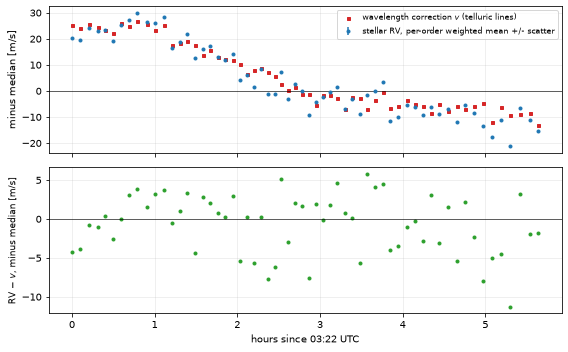

In [10]:
header = fits.getheader(exposures[0].path)
target = SkyCoord(header["RA2000"], header["DE2000"], unit=(u.hourangle, u.deg))
berv = []
for e in exposures:
    site = EarthLocation.from_geodetic(
        e.site.lon_deg * u.deg, e.site.lat_deg * u.deg, e.site.alt_m * u.m
    )
    when = Time(e.time_utc.replace(tzinfo=None), scale="utc")
    berv.append(
        target.radial_velocity_correction("barycentric", obstime=when, location=site).to_value(
            u.m / u.s
        )
    )

rv_bary = np.array([rv.loc[e.name, "po_wmean_kms"] * 1000 for e in exposures]) + np.array(berv)
rv_scatter = np.array([rv.loc[e.name, "po_wstd_kms"] * 1000 for e in exposures])
v_wave = np.array([json.loads(summary.loc[e.name, "wavesol_coeffs"])[0] * 1000 for e in exposures])
rv_corr = rv_bary - v_wave

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].errorbar(
    hours,
    rv_bary - np.median(rv_bary),
    yerr=rv_scatter,
    fmt="o",
    ms=3,
    label="stellar RV, per-order weighted mean +/- scatter",
)
axes[0].plot(
    hours,
    v_wave - np.median(v_wave),
    "s",
    ms=3,
    color="C3",
    label="wavelength correction $v$ (telluric lines)",
)
axes[0].set_ylabel("minus median [m/s]")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot(hours, rv_corr - np.median(rv_corr), "o", ms=3, color="C2")
axes[1].set_ylabel("RV $-$ $v$, minus median [m/s]", fontsize=9)
axes[1].set_xlabel(f"hours since {t0:%H:%M} UTC")
for ax in axes:
    ax.axhline(0, color="k", lw=0.6)
    ax.grid(alpha=0.25)
fig.tight_layout()

print(f"barycentric stellar RV: scatter {np.std(rv_bary):.1f} m/s")
print(
    f"wavelength correction v: median {np.median(v_wave):+.1f} m/s, "
    f"scatter {np.std(v_wave):.1f} m/s"
)
print(f"correlation of the two: {np.corrcoef(rv_bary, v_wave)[0, 1]:+.2f}")
print(f"RV - v: scatter {np.std(rv_corr):.1f} m/s")

The barycentric RV of the star drifts by about 40 m/s over the night (scatter
13.7 m/s), and the wavelength correction measured on the telluric lines follows the same
drift (correlation +0.96). The drift is therefore in the wavelength solution, not in the
star. On the corrected wavelength solution, $\mathrm{RV} - v$, the scatter drops to
3.8 m/s. Besides the drift, $v$ has a constant part of +67 m/s, an offset between the
wavelength solution and the line positions of the telluric model, which does not affect
the scatter.

The telluric lines are recorded in the same exposure as the star and their positions
are known, so they act as a simultaneous wavelength reference. Fitting them therefore
does more than correct the spectrum: it also corrects the wavelength solution of each
exposure.